In [198]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt

plt.style.use("dark_background")


In [199]:
data = yf.download("SPY GLD TSM BNP.PA 0700.HK XOM NESN.SW EURUSD=X HKDUSD=X CHFUSD=X",start="2016-01-01", end="2026-11-05")

[*********************100%***********************]  10 of 10 completed


In [200]:
prices = data.Close
asset_cols = ["SPY", "TSM", "BNP.PA", "GLD", "0700.HK", "XOM", "NESN.SW"]
fx_cols = ["EURUSD=X", "HKDUSD=X", "CHFUSD=X"]
prices = prices[asset_cols + fx_cols]

In [201]:
prices_usd = prices.copy()
prices_usd['BNP.PA'] = prices_usd['BNP.PA'] * prices_usd['EURUSD=X']
prices_usd['0700.HK'] = prices_usd['0700.HK'] * prices_usd['HKDUSD=X']
prices_usd['NESN.SW'] = prices_usd['NESN.SW'] * prices_usd['CHFUSD=X']

In [202]:
returns = prices_usd.dropna().pct_change().dropna()
log_returns = np.log(prices_usd.dropna()).diff().dropna()
weights = pd.Series({
    "SPY": 0.25,
    "TSM": 0.15,
    "BNP.PA": 0.15,
    "GLD": 0.15,
    "0700.HK": 0.10,
    "XOM": 0.10,
    "NESN.SW": 0.10,
    "EURUSD=X": -0.15,
})

In [203]:
portfolio_returns = (returns[weights.index] * weights).sum(axis=1)
print(portfolio_returns)


Date
2016-01-05    0.000432
2016-01-06   -0.011403
2016-01-07   -0.016685
2016-01-08   -0.010206
2016-01-11   -0.005103
                ...   
2026-10-29   -0.006575
2026-10-30   -0.015430
2026-11-02   -0.001058
2026-11-03    0.003581
2026-11-04    0.011453
Length: 2551, dtype: float64


In [204]:
def historical_var(returns, confidence, value):
    quantile_level = 1 - confidence
    quantile_return = returns.quantile(quantile_level)
    return quantile_return * value * (-1)
portfolio_value = 1000000
#attendu que la perte dépasse 23889 dollars 1 jour sur 100

In [205]:
var_99 = historical_var(portfolio_returns, 0.99, portfolio_value)
var_975 = historical_var(portfolio_returns, 0.975, portfolio_value)
var_95 = historical_var(portfolio_returns, 0.95, portfolio_value)
var_99_250d = historical_var(portfolio_returns.tail(250), 0.99, portfolio_value)
print(f"VaR 99 % = {var_99} USD")
print(f"VaR 97.5 % = {var_975} USD")
print(f"VaR 95 % = {var_95} USD")
print(f"VaR 99 % 250 days = {var_99_250d} USD")

VaR 99 % = 23888.437782279365 USD
VaR 97.5 % = 18975.63063241908 USD
VaR 95 % = 13970.104786672004 USD
VaR 99 % 250 days = 23520.095213740507 USD


In [206]:
def historical_es(returns, confidence, value):
    quantile_level = 1- confidence
    tail_returns = returns[returns <= returns.quantile(quantile_level)]
    return tail_returns.mean()*value*-1
print(f"Estimated shortfall 99% = {historical_es(portfolio_returns,0.99,portfolio_value)} USD")
print(f"Estimated shortfall 97.5% = {historical_es(portfolio_returns,0.975,portfolio_value)} USD")
print(f"Estimated shortfall 95% = {historical_es(portfolio_returns,0.95,portfolio_value)} USD")


Estimated shortfall 99% = 38114.8992146071 USD
Estimated shortfall 97.5% = 27939.439297277346 USD
Estimated shortfall 95% = 22170.767568355375 USD


In [207]:
below_var = portfolio_returns [portfolio_returns <= portfolio_returns.quantile(0.01)]
estimated_shortfall = below_var.mean()*portfolio_value*-1
ratio = estimated_shortfall/var_99
print(f"Estimated shortfall / VaR 99% = {ratio}")

Estimated shortfall / VaR 99% = 1.5955375383685007


In [208]:
below_var.index.year.value_counts().sort_index()

Date
2016     2
2018     1
2020    12
2021     1
2022     3
2023     1
2024     1
2025     2
2026     3
Name: count, dtype: int64

In [209]:
rolling_var = portfolio_returns.rolling(250).quantile(0.01)
rolling_var_usd = rolling_var*portfolio_value*-1
rolling_var_usd

Date
2016-01-05             NaN
2016-01-06             NaN
2016-01-07             NaN
2016-01-08             NaN
2016-01-11             NaN
                  ...     
2026-10-29    23520.095214
2026-10-30    23520.095214
2026-11-02    23520.095214
2026-11-03    23520.095214
2026-11-04    23520.095214
Length: 2551, dtype: float64

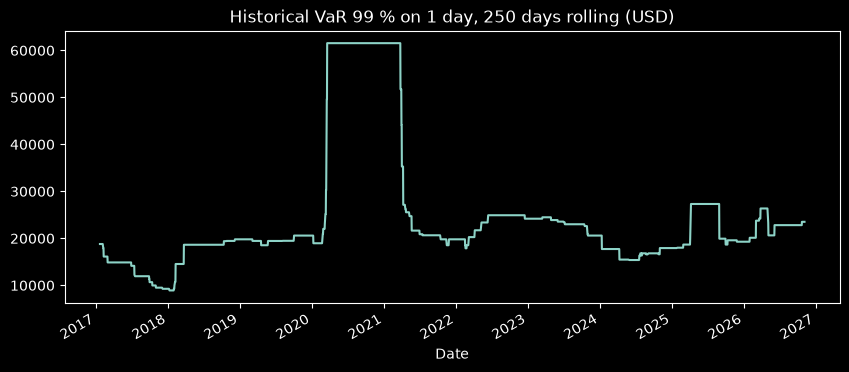

In [213]:
rolling_var_usd.plot(title="Historical VaR 99 % on 1 day, 250 days rolling (USD)", figsize=(10, 4));